# SSA publication and aggregate coverage

The DHS Program Indicator Data API, The Demographic and Health Surveys (DHS) Program. ICF. Originally funded by the United States Agency for International Development (USAID). Available from https://api.dhsprogram.com/. See fetch_dates for access times. SurveyBridge AI is independent of The DHS Program.

Counts describe retrieved records, not population health trends. Read ssa_summary.md and ssa_comparability_report.md. Report tables are not automatically extracted.

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
root = Path.cwd()
manifest = json.loads((root/'ssa_run_manifest.json').read_text(encoding='utf-8'))
for name, sha in manifest['checksums'].items():
    assert hashlib.sha256((root/name).read_bytes()).hexdigest() == sha, name
from surveybridge.services.provenance import verify_project
projects = json.loads((root/'ssa_source_projects.json').read_text(encoding='utf-8'))
for project in projects:
    assert verify_project(project)
records = json.loads((root/'ssa_observations.json').read_text(encoding='utf-8'))
assert sorted(records, key=lambda r:r['source_row_id']) == sorted([r for p in projects for r in p['observations']], key=lambda r:r['source_row_id'])
print('All archived project lineages and exported checksums verified')

All archived project lineages and exported checksums verified


In [2]:
summary = json.loads((root/'ssa_summary.json').read_text(encoding='utf-8'))
print(summary['completeness'])
print(summary['warnings'])
print(summary['availability_statuses'])
latest = pd.read_csv(root/'latest_survey_releases.csv')
display(latest)

{'completed': 126, 'failed': 0, 'indicator_extraction_complete': True, 'pending': 0, 'publication_discovery_complete': True, 'tasks_total': 126}
['Cross-survey comparability remains unverified; inspect per-indicator blocks, survey designs and population strata before comparing estimates', 'Official report exists while API survey status is not Completed', 'PDF cover date 2026-06 differs from catalog publication date 2026-07; both preserved']
{'AVAILABLE_SURVEY_NO_INDICATOR_DATA': 373, 'OBSERVED': 455}


,country_id,report_id,publication_date,date_precision,survey_id,source_url,report_type,source_states,fieldwork_start,fieldwork_end,latest_fieldwork_end,unknown_publication_dates,last_checked_utc
0,AO,FR396,2025-05,month,AO2023DHS,https://www.dhsprogram.com/pubs/pdf/FR396/FR39...,DHS Final Reports,"[""API_INDICATOR_AVAILABLE"", ""REPORT_METADATA_O...",2023-08-01,2024-01-01,2024-01-01,0,2026-10-31T06:37:12.159102+00:00
1,BF,FR378,2023-08,month,BF2021DHS,https://www.dhsprogram.com/pubs/pdf/FR378/FR37...,DHS Final Reports,"[""API_INDICATOR_AVAILABLE"", ""REPORT_METADATA_O...",2021-07-01,2021-12-01,2021-12-01,0,2026-10-31T06:37:12.159102+00:00
2,BJ,FR350,2019-04,month,BJ2017DHS,https://www.dhsprogram.com/pubs/pdf/FR350/FR35...,DHS Final Reports,"[""API_INDICATOR_AVAILABLE"", ""REPORT_METADATA_O...",2017-11-01,2018-02-01,2018-02-01,0,2026-10-31T06:37:12.159102+00:00
3,BT,FR3,1989-08,month,BT1988DHS,https://www.dhsprogram.com/pubs/pdf/FR3/FR3.pdf,DHS Final Reports,"[""API_INDICATOR_AVAILABLE"", ""REPORT_METADATA_O...",1988-08-01,1988-12-01,1988-12-01,0,2026-10-31T06:37:12.159102+00:00
4,BU,FR335,2017-12,month,BU2016DHS,https://www.dhsprogram.com/pubs/pdf/FR335/FR33...,DHS Final Reports,"[""API_INDICATOR_AVAILABLE"", ""REPORT_METADATA_O...",2016-10-01,2017-02-01,2017-02-01,0,2026-10-31T06:37:12.159102+00:00
5,CD,FR393,2025-08,month,CD2023DHS,https://www.dhsprogram.com/pubs/pdf/FR393/FR39...,DHS Final Reports,"[""API_INDICATOR_AVAILABLE"", ""REPORT_METADATA_O...",2023-10-01,2024-01-01,2024-01-01,0,2026-10-31T06:37:12.159102+00:00
6,CF,FR263,2012-04,month,CF2010OTH,https://www.dhsprogram.com/pubs/pdf/FR263/FR26...,Other Final Reports,"[""REPORT_METADATA_ONLY""]",2009-06-01,2010-09-01,2010-09-01,0,2026-10-31T06:37:12.159102+00:00
7,CG,PR167,2026-08,month,CG2025DHS,https://dhsprogram.com/pubs/pdf/PR167/PR167.pdf,Preliminary Reports/Key Indicators Reports,"[""REPORT_METADATA_ONLY""]",2025-08-01,2025-12-01,2025-12-01,0,2026-10-31T06:37:12.159102+00:00
8,CI,FR385,2023-09,month,CI2021DHS,https://www.dhsprogram.com/pubs/pdf/FR385/FR38...,DHS Final Reports,"[""API_INDICATOR_AVAILABLE"", ""REPORT_METADATA_O...",2021-09-01,2021-12-01,2021-12-01,0,2026-10-31T06:37:12.159102+00:00
9,CM,MIS43,2023-10,month,CM2022MIS,https://www.dhsprogram.com/pubs/pdf/MIS43/MIS4...,MIS Final Reports,"[""API_INDICATOR_AVAILABLE"", ""REPORT_METADATA_O...",2022-08-01,2022-11-01,2022-11-01,0,2026-10-31T06:37:12.159102+00:00


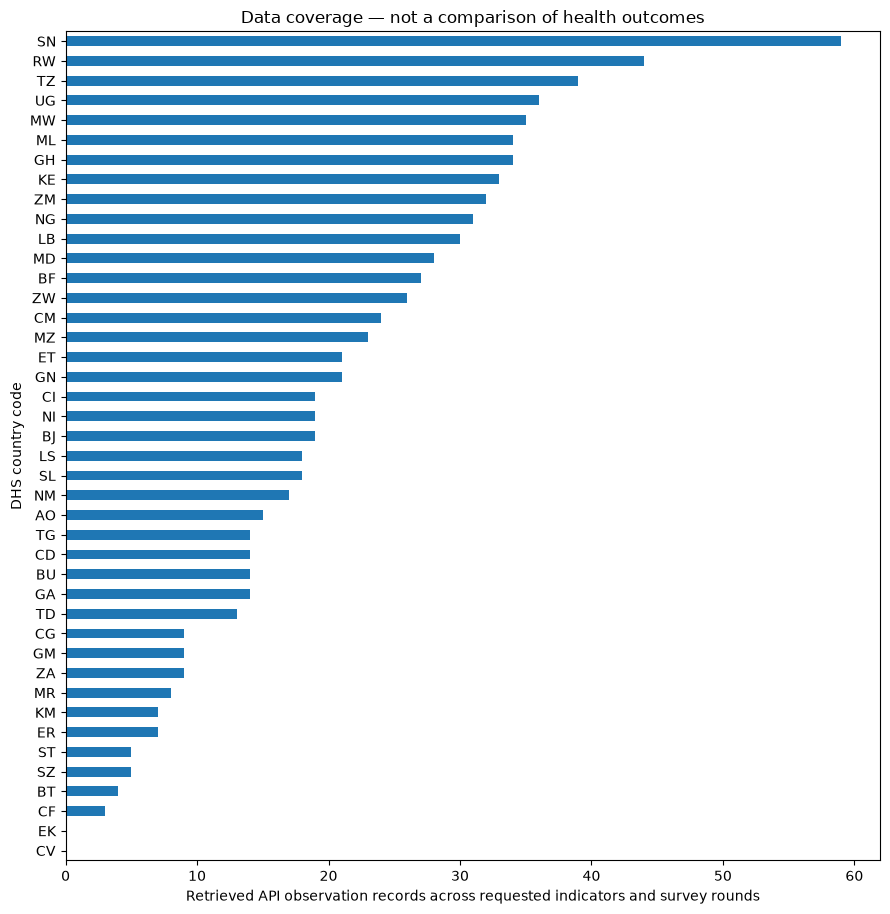

In [3]:
import matplotlib.pyplot as plt
counts = pd.Series(summary['country_totals']).sort_values()
if not counts.empty:
    ax = counts.plot.barh(figsize=(9, max(4, len(counts)*0.22)))
    ax.set_xlabel('Retrieved API observation records across requested indicators and survey rounds')
    ax.set_ylabel('DHS country code')
    ax.set_title('Data coverage — not a comparison of health outcomes')
    plt.tight_layout()
    plt.show()
# No report estimate extraction, annual interpolation, pooled indicators or significance tests.